In [1]:
# ============================================
# GitHub Developer Collaboration Network
# Using PageRank and Graph Mining
# ============================================

!pip -q install networkx pandas matplotlib seaborn

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ============================================
# STEP 2: Create a manageable GitHub
# developer collaboration dataset
# ============================================

data = {
    "developer_1": [
        "dev_A", "dev_A", "dev_A", "dev_A",
        "dev_B", "dev_B", "dev_B",
        "dev_C", "dev_C",
        "dev_D", "dev_D",
        "dev_E", "dev_F", "dev_G",
        "dev_H", "dev_I", "dev_J"
    ],

    "developer_2": [
        "dev_B", "dev_C", "dev_D", "dev_E",
        "dev_C", "dev_D", "dev_E",
        "dev_D", "dev_E",
        "dev_E", "dev_F",
        "dev_F", "dev_G", "dev_H",
        "dev_I", "dev_J", "dev_K"
    ],

    "collaboration_count": [
        12, 8, 6, 4,
        10, 7, 5,
        9, 6,
        8, 5,
        7, 6, 5,
        4, 3, 2
    ]
}

df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

df.head(10)

Dataset loaded successfully!
Number of records: 17
Number of columns: 3


,developer_1,developer_2,collaboration_count
0,dev_A,dev_B,12
1,dev_A,dev_C,8
2,dev_A,dev_D,6
3,dev_A,dev_E,4
4,dev_B,dev_C,10
5,dev_B,dev_D,7
6,dev_B,dev_E,5
7,dev_C,dev_D,9
8,dev_C,dev_E,6
9,dev_D,dev_E,8


In [3]:
# ============================================
# STEP 3: Dataset structure and characteristics
# ============================================

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nBasic Statistical Summary:")
display(df.describe())

Dataset Shape: (17, 3)

Column Names:
['developer_1', 'developer_2', 'collaboration_count']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17 entries, 0 to 16
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   developer_1          17 non-null     object
 1   developer_2          17 non-null     object
 2   collaboration_count  17 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 540.0+ bytes

Basic Statistical Summary:


,collaboration_count
count,17.000000
mean,6.294118
std,2.568188
min,2.000000
25%,5.000000
50%,6.000000
75%,8.000000
max,12.000000


In [4]:
# ============================================
# STEP 4: Missing Value Analysis
# ============================================

print("Missing Values in Each Column:")
missing_values = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_df)

Missing Values in Each Column:


,Missing Values,Missing Percentage
developer_1,0,0.0
developer_2,0,0.0
collaboration_count,0,0.0


In [5]:
# ============================================
# STEP 5: Duplicate Record Analysis
# ============================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

if duplicate_count == 0:
    print("No duplicate records found.")
else:
    print("Duplicate records found and require removal.")

Number of duplicate records: 0
No duplicate records found.


In [6]:
# ============================================
# STEP 6: Data Cleaning
# ============================================

df_clean = df.copy()

# Remove rows containing missing values
df_clean = df_clean.dropna()

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates()

# Remove self-collaboration records
df_clean = df_clean[
    df_clean["developer_1"] != df_clean["developer_2"]
]

# Ensure collaboration count is numeric
df_clean["collaboration_count"] = pd.to_numeric(
    df_clean["collaboration_count"],
    errors="coerce"
)

# Remove invalid collaboration values
df_clean = df_clean[
    df_clean["collaboration_count"] > 0
]

df_clean = df_clean.reset_index(drop=True)

print("Data cleaning completed successfully!")
print("Original records:", len(df))
print("Records after cleaning:", len(df_clean))

display(df_clean.head(10))

Data cleaning completed successfully!
Original records: 17
Records after cleaning: 17


,developer_1,developer_2,collaboration_count
0,dev_A,dev_B,12
1,dev_A,dev_C,8
2,dev_A,dev_D,6
3,dev_A,dev_E,4
4,dev_B,dev_C,10
5,dev_B,dev_D,7
6,dev_B,dev_E,5
7,dev_C,dev_D,9
8,dev_C,dev_E,6
9,dev_D,dev_E,8


In [7]:
# ============================================
# STEP 7: Basic Exploratory Data Analysis
# ============================================

unique_developers = pd.unique(
    df_clean[["developer_1", "developer_2"]].values.ravel()
)

print("Number of unique developers:", len(unique_developers))
print("Number of collaboration relationships:", len(df_clean))
print("Total collaboration interactions:",
      df_clean["collaboration_count"].sum())

print("\nCollaboration Count Statistics:")
display(df_clean["collaboration_count"].describe())

Number of unique developers: 11
Number of collaboration relationships: 17
Total collaboration interactions: 107

Collaboration Count Statistics:


,collaboration_count
count,17.000000
mean,6.294118
std,2.568188
min,2.000000
25%,5.000000
50%,6.000000
75%,8.000000
max,12.000000


In [8]:
# ============================================
# STEP 8: Construct Developer Collaboration Graph
# ============================================

G = nx.Graph()

for _, row in df_clean.iterrows():
    dev1 = row["developer_1"]
    dev2 = row["developer_2"]
    weight = row["collaboration_count"]

    G.add_edge(dev1, dev2, weight=weight)

print("Graph constructed successfully!")
print("Number of developers (nodes):", G.number_of_nodes())
print("Number of collaboration links (edges):", G.number_of_edges())

Graph constructed successfully!
Number of developers (nodes): 11
Number of collaboration links (edges): 17


In [9]:
# ============================================
# STEP 9: Graph Statistics
# ============================================

num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()

density = nx.density(G)
avg_degree = sum(dict(G.degree()).values()) / num_nodes

print("Graph Statistics")
print("-----------------------------")
print("Number of Nodes:", num_nodes)
print("Number of Edges:", num_edges)
print("Graph Density:", round(density, 4))
print("Average Degree:", round(avg_degree, 2))
print("Connected Components:", nx.number_connected_components(G))

Graph Statistics
-----------------------------
Number of Nodes: 11
Number of Edges: 17
Graph Density: 0.3091
Average Degree: 3.09
Connected Components: 1


In [10]:
# ============================================
# STEP 10: Degree Analysis
# ============================================

degree_data = pd.DataFrame(
    G.degree(),
    columns=["Developer", "Degree"]
)

degree_data = degree_data.sort_values(
    by="Degree",
    ascending=False
)

print("Top Developers by Number of Connections:")
display(degree_data.head(10))

Top Developers by Number of Connections:


,Developer,Degree
3,dev_D,5
4,dev_E,5
0,dev_A,4
2,dev_C,4
1,dev_B,4
5,dev_F,3
6,dev_G,2
7,dev_H,2
8,dev_I,2
9,dev_J,2


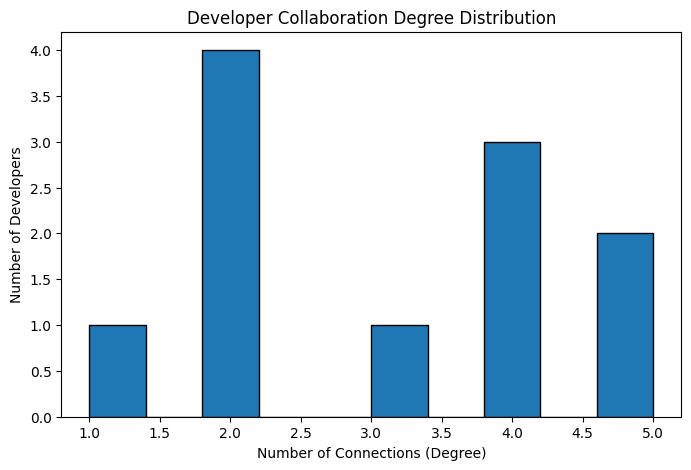

In [11]:
# ============================================
# STEP 11: Degree Distribution
# ============================================

plt.figure(figsize=(8, 5))

plt.hist(
    degree_data["Degree"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Number of Connections (Degree)")
plt.ylabel("Number of Developers")
plt.title("Developer Collaboration Degree Distribution")

plt.show()

In [12]:
# ============================================
# STEP 12: PageRank Analysis
# ============================================

pagerank_scores = nx.pagerank(
    G,
    weight="weight"
)

pagerank_df = pd.DataFrame(
    pagerank_scores.items(),
    columns=["Developer", "PageRank"]
)

pagerank_df = pagerank_df.sort_values(
    by="PageRank",
    ascending=False
).reset_index(drop=True)

print("Top Developers According to PageRank:")
display(pagerank_df.head(10))

Top Developers According to PageRank:


,Developer,PageRank
0,dev_D,0.118885
1,dev_B,0.110015
2,dev_C,0.107495
3,dev_E,0.106553
4,dev_A,0.098190
5,dev_I,0.087120
6,dev_H,0.086359
7,dev_F,0.085692
8,dev_J,0.080120
9,dev_G,0.078695


In [13]:
# ============================================
# STEP 13: Degree vs PageRank Analysis
# ============================================

comparison_df = degree_data.merge(
    pagerank_df,
    on="Developer"
)

print("Degree and PageRank Comparison:")
display(
    comparison_df.sort_values(
        by="PageRank",
        ascending=False
    ).head(10)
)

correlation = comparison_df["Degree"].corr(
    comparison_df["PageRank"]
)

print("\nCorrelation between Degree and PageRank:",
      round(correlation, 4))

Degree and PageRank Comparison:


,Developer,Degree,PageRank
0,dev_D,5,0.118885
4,dev_B,4,0.110015
3,dev_C,4,0.107495
1,dev_E,5,0.106553
2,dev_A,4,0.098190
8,dev_I,2,0.087120
7,dev_H,2,0.086359
5,dev_F,3,0.085692
9,dev_J,2,0.080120
6,dev_G,2,0.078695



Correlation between Degree and PageRank: 0.8918


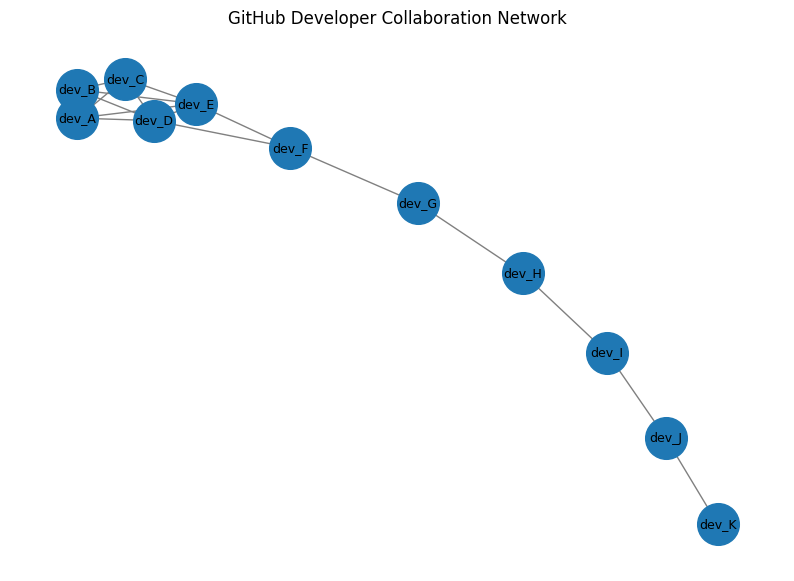

In [14]:
# ============================================
# STEP 14: Collaboration Network Visualization
# ============================================

plt.figure(figsize=(10, 7))

pos = nx.spring_layout(
    G,
    seed=42
)

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=900,
    font_size=9,
    edge_color="gray"
)

plt.title("GitHub Developer Collaboration Network")
plt.axis("off")
plt.show()

In [15]:
# ============================================
# STEP 15: Sampling Methodology
# ============================================

# Take a 60% random sample
sample_df = df_clean.sample(
    frac=0.60,
    random_state=42
)

print("Sampling completed successfully!")
print("Original dataset records:", len(df_clean))
print("Sampled records:", len(sample_df))

display(sample_df.head(10))

Sampling completed successfully!
Original dataset records: 17
Sampled records: 10


,developer_1,developer_2,collaboration_count
0,dev_A,dev_B,12
1,dev_A,dev_C,8
5,dev_B,dev_D,7
15,dev_I,dev_J,3
11,dev_E,dev_F,7
14,dev_H,dev_I,4
8,dev_C,dev_E,6
13,dev_G,dev_H,5
2,dev_A,dev_D,6
9,dev_D,dev_E,8


In [16]:
# ============================================
# STEP 16: Full Dataset vs Sample Comparison
# ============================================

comparison = pd.DataFrame({
    "Measure": [
        "Number of Records",
        "Unique Developers",
        "Total Collaboration Count"
    ],

    "Full Dataset": [
        len(df_clean),
        len(pd.unique(df_clean[["developer_1", "developer_2"]].values.ravel())),
        df_clean["collaboration_count"].sum()
    ],

    "Sample": [
        len(sample_df),
        len(pd.unique(sample_df[["developer_1", "developer_2"]].values.ravel())),
        sample_df["collaboration_count"].sum()
    ]
})

display(comparison)

,Measure,Full Dataset,Sample
0,Number of Records,17,10
1,Unique Developers,11,10
2,Total Collaboration Count,107,66


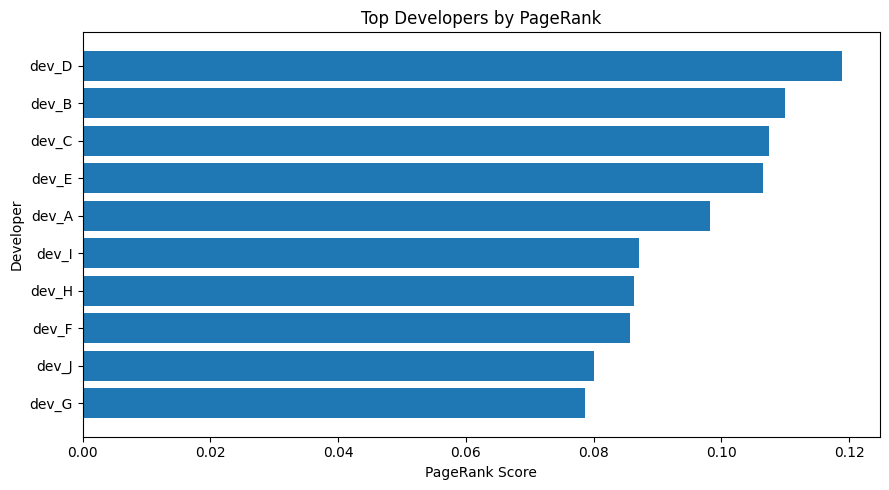

In [17]:
# ============================================
# STEP 17: Top Developers by PageRank
# ============================================

top_pagerank = pagerank_df.head(10).sort_values(
    by="PageRank"
)

plt.figure(figsize=(9, 5))

plt.barh(
    top_pagerank["Developer"],
    top_pagerank["PageRank"]
)

plt.xlabel("PageRank Score")
plt.ylabel("Developer")
plt.title("Top Developers by PageRank")

plt.tight_layout()
plt.show()

In [18]:
# ============================================
# STEP 18: Final Developer Ranking
# ============================================

final_results = comparison_df.copy()

final_results["PageRank Rank"] = (
    final_results["PageRank"]
    .rank(ascending=False, method="min")
    .astype(int)
)

final_results = final_results.sort_values(
    by="PageRank",
    ascending=False
)

print("Final Developer Influence Ranking:")
display(final_results.head(10))

Final Developer Influence Ranking:


,Developer,Degree,PageRank,PageRank Rank
0,dev_D,5,0.118885,1
4,dev_B,4,0.110015,2
3,dev_C,4,0.107495,3
1,dev_E,5,0.106553,4
2,dev_A,4,0.098190,5
8,dev_I,2,0.087120,6
7,dev_H,2,0.086359,7
5,dev_F,3,0.085692,8
9,dev_J,2,0.080120,9
6,dev_G,2,0.078695,10


In [19]:
# ============================================
# STEP 19: Save Results
# ============================================

final_results.head(10).to_csv(
    "top_developers_pagerank.csv",
    index=False
)

comparison.to_csv(
    "sampling_comparison.csv",
    index=False
)

print("Result files saved successfully!")

Result files saved successfully!


Task 5 Regression Analysis and Hypothesis Testing


TASK 5: REGRESSION ANALYSIS
---------------------------
Slope: 0.013836
Intercept: 0.048144
R2 Score: 0.7952
MAE: 0.007478
RMSE: 0.009205

HYPOTHESIS TESTING
------------------
Pearson Correlation: 0.8918
P-value: 0.0002
Significance Level: 0.05
Reject Null Hypothesis
A statistically significant relationship exists.


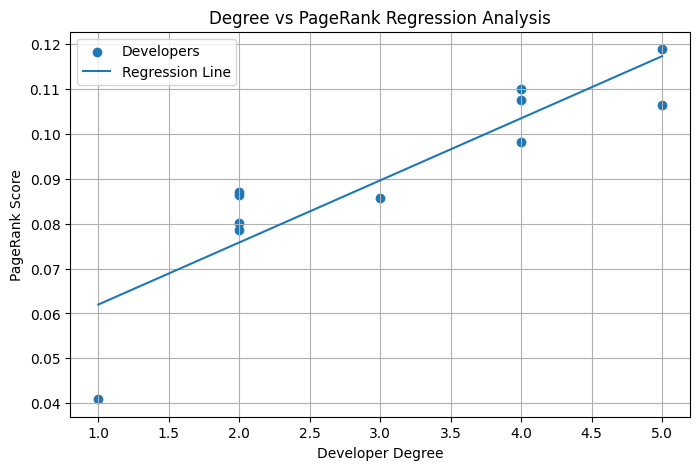

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prepare data
X = comparison_df[["Degree"]]
y = comparison_df["PageRank"]

# Linear Regression
model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Regression Results
print("TASK 5: REGRESSION ANALYSIS")
print("---------------------------")
print("Slope:", round(model.coef_[0], 6))
print("Intercept:", round(model.intercept_, 6))
print("R2 Score:", round(model.score(X, y), 4))
print("MAE:", round(mean_absolute_error(y, y_pred), 6))
print("RMSE:", round(np.sqrt(mean_squared_error(y, y_pred)), 6))

# Hypothesis Testing
r, p_value = pearsonr(X["Degree"], y)

print("\nHYPOTHESIS TESTING")
print("------------------")
print("Pearson Correlation:", round(r, 4))
print("P-value:", round(p_value, 4))
print("Significance Level: 0.05")

if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("A statistically significant relationship exists.")
else:
    print("Fail to Reject Null Hypothesis")
    print("A statistically significant relationship was not established.")

# Visualization
plt.figure(figsize=(8, 5))
plt.scatter(X["Degree"], y, label="Developers")
plt.plot(X["Degree"], y_pred, label="Regression Line")
plt.xlabel("Developer Degree")
plt.ylabel("PageRank Score")
plt.title("Degree vs PageRank Regression Analysis")
plt.legend()
plt.grid(True)
plt.show()

TASK 6: COMMUNITY DETECTION RESULTS
----------------------------------
Number of Communities: 2


,Developer,Community
0,dev_B,1
1,dev_E,1
2,dev_A,1
3,dev_D,1
4,dev_C,1
5,dev_K,2
6,dev_F,2
7,dev_J,2
8,dev_G,2
9,dev_H,2


Modularity Score: 0.2557


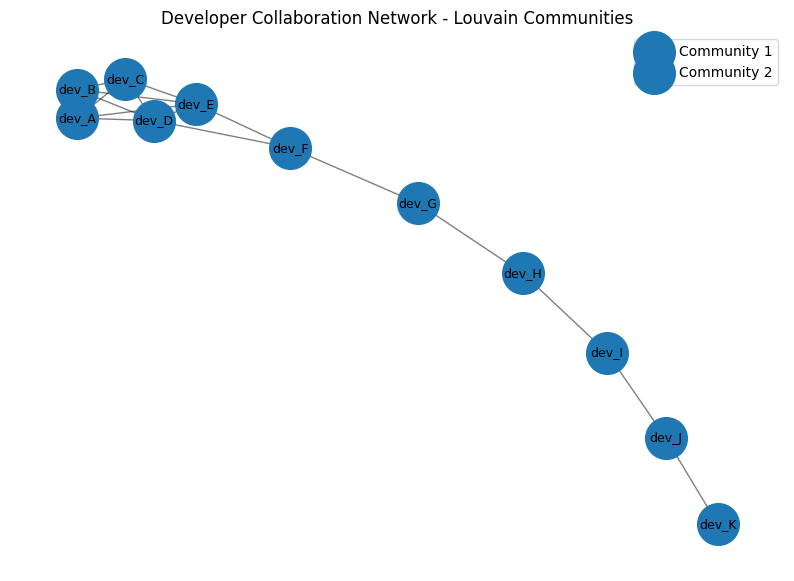

In [21]:
# TASK 6: Community Detection Using Louvain Algorithm

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Detect communities
communities = nx.community.louvain_communities(
    G,
    weight="weight",
    seed=42
)

# Community assignments
community_data = []

for community_id, community in enumerate(communities, start=1):
    for developer in community:
        community_data.append({
            "Developer": developer,
            "Community": community_id
        })

community_df = pd.DataFrame(community_data)

print("TASK 6: COMMUNITY DETECTION RESULTS")
print("----------------------------------")

print("Number of Communities:", len(communities))

display(community_df.sort_values("Community"))

# Modularity
modularity = nx.community.modularity(
    G,
    communities,
    weight="weight"
)

print("Modularity Score:", round(modularity, 4))

# Community Visualization
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))

for community_id, community in enumerate(communities):
    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=list(community),
        node_size=900,
        label=f"Community {community_id + 1}"
    )

nx.draw_networkx_edges(G, pos, alpha=0.5)
nx.draw_networkx_labels(G, pos, font_size=9)

plt.title("Developer Collaboration Network - Louvain Communities")
plt.legend()
plt.axis("off")
plt.show()

TASK 7: STREAMING DATA PROCESSING
--------------------------------
Event 1: dev_A collaborated with dev_B, count = 2
Event 2: dev_B collaborated with dev_D, count = 3
Event 3: dev_C collaborated with dev_E, count = 1
Event 4: dev_D collaborated with dev_F, count = 2
Event 5: dev_A collaborated with dev_G, count = 1
Event 6: dev_E collaborated with dev_H, count = 2
Event 7: dev_F collaborated with dev_I, count = 1
Event 8: dev_G collaborated with dev_J, count = 3
Event 9: dev_H collaborated with dev_A, count = 2
Event 10: dev_I collaborated with dev_D, count = 1

STREAMING SUMMARY
-----------------
Processed Events: 10
Updated Nodes: 11
Updated Edges: 23
Total Processing Time: 7e-05 seconds
Average Event Latency: 0.007 milliseconds
Throughput: 142517.14 events/second

UPDATED DEVELOPER RANKING


,Developer,Updated_PageRank
3,dev_D,0.136168
1,dev_B,0.123241
0,dev_A,0.115865
4,dev_E,0.114323
2,dev_C,0.109027
5,dev_F,0.088083
6,dev_G,0.083320
7,dev_H,0.071736
9,dev_J,0.069105
8,dev_I,0.060812


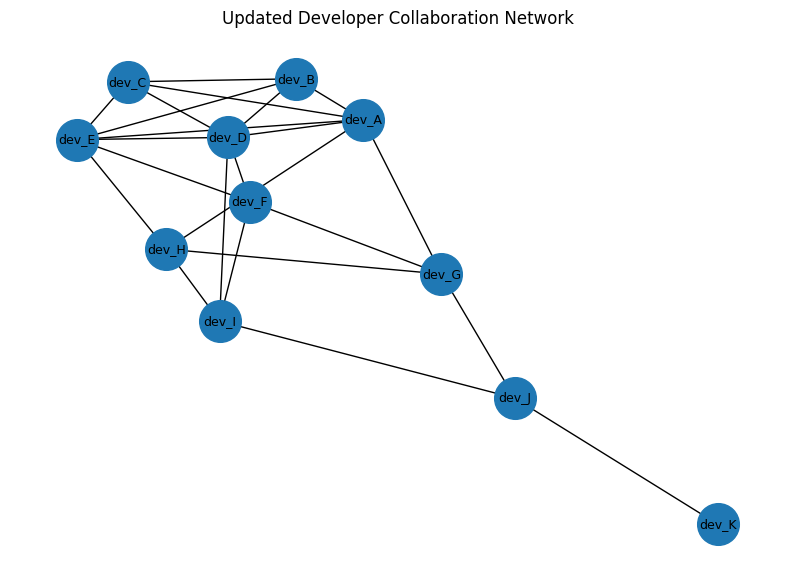

In [22]:
# TASK 7: Simulated Streaming Data Processing

import time
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Simulated incoming collaboration events
stream_events = [
    ("dev_A", "dev_B", 2),
    ("dev_B", "dev_D", 3),
    ("dev_C", "dev_E", 1),
    ("dev_D", "dev_F", 2),
    ("dev_A", "dev_G", 1),
    ("dev_E", "dev_H", 2),
    ("dev_F", "dev_I", 1),
    ("dev_G", "dev_J", 3),
    ("dev_H", "dev_A", 2),
    ("dev_I", "dev_D", 1)
]

# Create a copy of the original graph
stream_graph = G.copy()

processed_events = 0
processing_times = []

print("TASK 7: STREAMING DATA PROCESSING")
print("--------------------------------")

for dev1, dev2, count in stream_events:

    start_time = time.perf_counter()

    if stream_graph.has_edge(dev1, dev2):
        stream_graph[dev1][dev2]["weight"] += count
    else:
        stream_graph.add_edge(
            dev1,
            dev2,
            weight=count
        )

    processed_events += 1

    processing_times.append(
        time.perf_counter() - start_time
    )

    print(
        f"Event {processed_events}: "
        f"{dev1} collaborated with {dev2}, "
        f"count = {count}"
    )

# Streaming Summary
total_time = sum(processing_times)

print("\nSTREAMING SUMMARY")
print("-----------------")
print("Processed Events:", processed_events)
print("Updated Nodes:", stream_graph.number_of_nodes())
print("Updated Edges:", stream_graph.number_of_edges())

print(
    "Total Processing Time:",
    round(total_time, 6),
    "seconds"
)

print(
    "Average Event Latency:",
    round(np.mean(processing_times) * 1000, 4),
    "milliseconds"
)

print(
    "Throughput:",
    round(processed_events / total_time, 2),
    "events/second"
)

# Updated PageRank
stream_pagerank = nx.pagerank(
    stream_graph,
    weight="weight"
)

stream_results = pd.DataFrame(
    stream_pagerank.items(),
    columns=["Developer", "Updated_PageRank"]
)

stream_results = stream_results.sort_values(
    "Updated_PageRank",
    ascending=False
)

print("\nUPDATED DEVELOPER RANKING")

display(stream_results)

# Updated Network Visualization
plt.figure(figsize=(10, 7))

pos = nx.spring_layout(
    stream_graph,
    seed=42
)

nx.draw_networkx(
    stream_graph,
    pos,
    with_labels=True,
    node_size=900,
    font_size=9
)

plt.title("Updated Developer Collaboration Network")
plt.axis("off")
plt.show()